In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
hyper = neurons.HyperConfig1(nd=300, ns=200, n=10, b=2.0, bk=3.5, beta=4.53061)
hyperD = neurons.HyperDynConfig1(b=2.00, bk=3.5, beta=4.53061)
# neuron = neurons.Neuron_Decay_Int(hyper)
# neuron = neurons.Neuron_Decay_NonInt(hyper)
# neuron = neurons.Neuron_Decay_Int_NoNonLinearity(hyper)
neuron = neurons.Neuron_Decay_Int_Variable_n(hyper)
xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)
# xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=hyper.nd, ns=hyper.ns, coeff=4, key=jax.random.PRNGKey(42))

my_driver = driver.Driver1_bScan(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(11111),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

# my_driver = driver.Driver1_NoisyRecall_SomaNoise3(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     noise_level=0.0, 
#     max_Y=3.0,
#     rng=jax.random.PRNGKey(223313),
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000,
#     n_tested_patterns=1000,
# )

# my_driver = driver.Driver1_noNonlinearity(
#     neuron=neuron,
#     xs_generator=xs_gen,
#     rng=jax.random.PRNGKey(333),
#     hyperD=hyperD,
#     initial_state=None,
#     resample_every=1000,
#     n_tested_patterns=1000,
# )

In [3]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([2.0]),
)

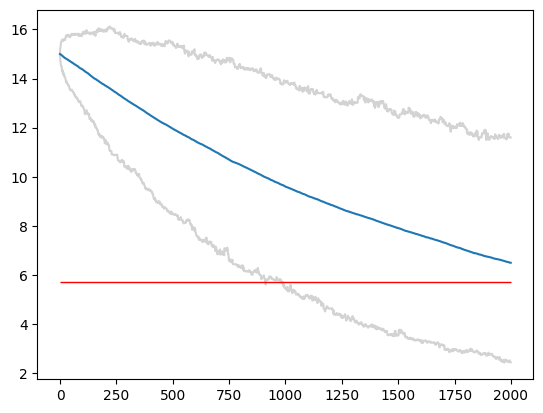

In [4]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

In [11]:
utils.capacity_numba(my_driver.transient_record, my_driver.steady_record)

array([0.])

(array([37., 72., 97., 59., 17., 12.,  4.,  1.,  0.,  1.]),
 array([0.82559669, 0.88242501, 0.93925327, 0.99608159, 1.05290985,
        1.10973811, 1.16656649, 1.22339475, 1.28022313, 1.33705139,
        1.39387965]),
 <BarContainer object of 10 artists>)

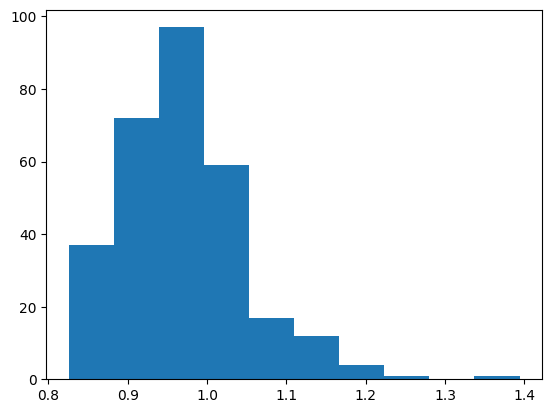

In [8]:
plt.hist(jnp.linalg.norm(my_driver.state.w, axis=-1))

In [18]:
jnp.mean(jnp.linalg.norm(my_driver.state.w, axis=-1))

Array(1.0021906, dtype=float32)

### Test for parrallel state driver

In [20]:
hyper = neurons.HyperConfig1(nd=300, ns=200, n=10, b=2.0, bk=3.5, beta=4.53061)
hyperD = neurons.HyperDynConfig1(b=jnp.array([2.00, 2.00, 2.00]), bk=jnp.array([3.5, 4.5, 5.5]), beta=jnp.array([3.8745, 8.41227, 14.3257]))
neuron = neurons.Neuron_Decay_Int_Variable_n(hyper)
xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)

my_driver = driver.Driver1_parallel_states(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(11111),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

In [21]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=None,
)

In [22]:
utils.capacity_numba(my_driver.transient_record, my_driver.steady_record)

array([884.        , 744.66666667, 557.33333333])

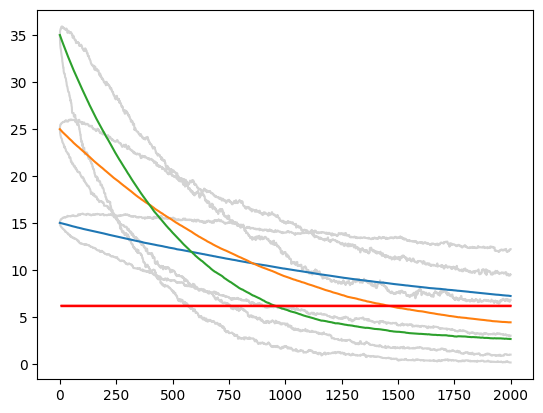

In [23]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

0.99534994
0.9893463
0.9844212


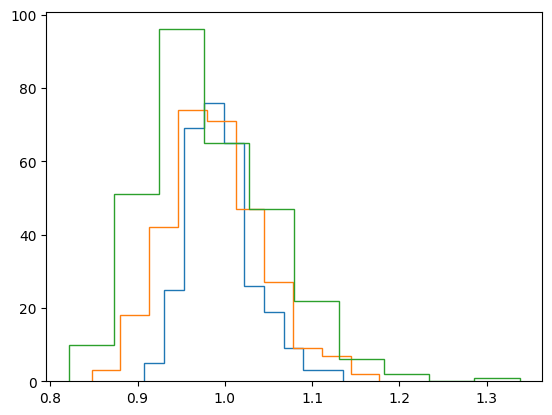

In [24]:
norms1 = jnp.linalg.norm(my_driver.state.w[0], axis=-1)
norms2 = jnp.linalg.norm(my_driver.state.w[1], axis=-1)
norms3 = jnp.linalg.norm(my_driver.state.w[2], axis=-1)

plt.hist(norms1,histtype='step')
plt.hist(norms2,histtype='step')
plt.hist(norms3,histtype='step')

print(jnp.mean(norms1))
print(jnp.mean(norms2))
print(jnp.mean(norms3))